# 05. Modelos ajustados y validación

        **Objetivo:** reducir el error al predecir la **carga de primera falla (N)** a partir de geometría previa al ensayo.
        Se mantiene la tabla y los splits de la Semana 5; el cambio experimental es el ajuste de modelos.

In [1]:
from pathlib import Path
import sys, json, random
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, GridSearchCV

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/feature_engineering.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.feature_engineering import TARGET, make_pipeline, nominal_groups
from src.transformaciones_eda import GEOMETRY
from src import reporte_ajuste as informe

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
RUN_DIR = ROOT / 'reports/modelos_ajustados'
pd.set_option('display.max_colwidth', 90)

## 5.1 Datos e información de entrada

        El objetivo es una fuerza medida, no una clase de rotura. Identificadores, cargas posteriores,
        desplazamientos y energías no se usan como predictores. [Definiciones de variables](../docs/diccionario_datos.md).

In [2]:
datos, ruta_datos, hash_datos = informe.datos_congelados()
X = datos[GEOMETRY].copy()
y = datos[TARGET].copy()
assert TARGET not in X.columns and 'Case_n' not in X.columns
display(informe.tabla_variables(datos).style.hide(axis='index').format({'Ejemplo observado': '{:.3f}'}))
print('Snapshot histórico verificado · SHA-256:', hash_datos)

Variable,Papel,Unidad,Ejemplo observado,Tratamiento
Número de celdas en Y,Entrada previa al ensayo,conteo,4.000,"Mediana, filtro de constantes y escala en train"
Altura de fibra,Entrada previa al ensayo,mm,1.000,"Mediana, filtro de constantes y escala en train"
Ancho de fibra,Entrada previa al ensayo,mm,2.400,"Mediana, filtro de constantes y escala en train"
Longitud total de fibras,Entrada previa al ensayo,mm,2685.820,"Mediana, filtro de constantes y escala en train"
Volumen total de fibras,Entrada previa al ensayo,mm³,6435.300,"Mediana, filtro de constantes y escala en train"
Altura de pivote,Entrada previa al ensayo,mm,1.000,"Mediana, filtro de constantes y escala en train"
Radio de pivote,Entrada previa al ensayo,mm,0.500,Filtro de constantes ajustado en train
Número de pivotes,Entrada previa al ensayo,conteo,113.000,"Mediana, filtro de constantes y escala en train"
Volumen total de pivotes,Entrada previa al ensayo,mm³,88.710,"Mediana, filtro de constantes y escala en train"
Volumen total del espécimen,Entrada previa al ensayo,mm³,6249.740,"Mediana, filtro de constantes y escala en train"


Snapshot histórico verificado · SHA-256: 2d0a17f54bdc6a6361aaa6e25a57cf67775c7d47a5e2adefb408f114defa21f8


## 5.2 Particiones externas e internas

        **Configuración:** misma cantidad de celdas en Y, altura de fibra y altura de pivote.
        **Familia:** misma cantidad de celdas en Y; identifica una arquitectura del diseño.
        El protocolo principal reserva configuraciones y el secundario familias completas.
        La búsqueda de parámetros ocurre únicamente dentro del entrenamiento de cada split externo.

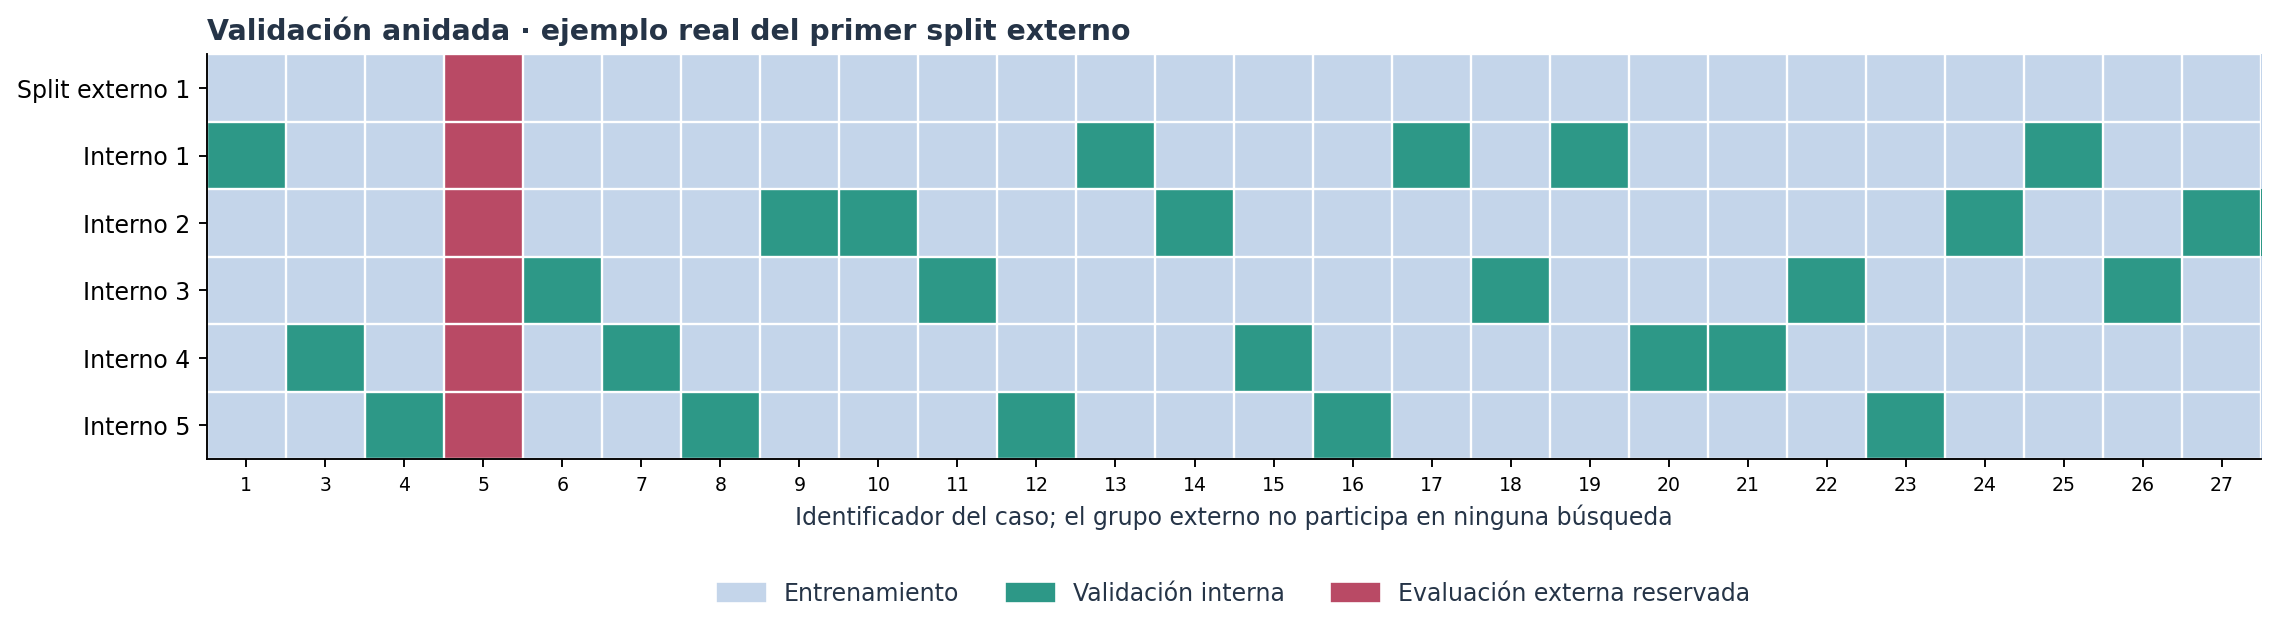

In [3]:
# Se recuperan los casos del split histórico; no se genera otra partición final.
splits, registros = informe.particiones_historicas(datos)
grupos_config = nominal_groups(datos, ['n_cells_Y', 'Fiber_height', 'Pivot_height'])
grupos_familia = datos.n_cells_Y.astype(int).astype(str)
train, test = splits['configuracion'][0]
assert set(grupos_config.iloc[train]).isdisjoint(grupos_config.iloc[test])

# Índices internos relativos exclusivamente al bloque train externo.
cv_interna = list(GroupKFold(n_splits=5).split(X.iloc[train], y.iloc[train], grupos_config.iloc[train]))
for ajuste, validacion in cv_interna:
    assert set(grupos_config.iloc[train].iloc[ajuste]).isdisjoint(grupos_config.iloc[train].iloc[validacion])
    assert set(train[ajuste]).isdisjoint(test) and set(train[validacion]).isdisjoint(test)

# En el protocolo secundario se excluye una familia también dentro del train externo.
train_familia, test_familia = splits['familia'][0]
cv_familia = list(LeaveOneGroupOut().split(
    X.iloc[train_familia], y.iloc[train_familia], grupos_familia.iloc[train_familia]))
assert set(grupos_familia.iloc[train_familia]).isdisjoint(grupos_familia.iloc[test_familia])
display(Image(filename=str(informe.figura_particiones(datos, registros, cv_interna, RUN_DIR))))

## 5.3 Preprocesamiento: ajuste solo en train

        Geometría original → imputación de mediana → filtro de constantes → estandarización → regresor.
        No se aplican PCA, target encoding, balanceo ni nuevas características en esta comparación.

In [4]:
# Ejecución real del pipeline sobre el train del primer split externo.
ejemplo_pipeline = make_pipeline('A', alpha=1.0)
ejemplo_pipeline.fit(X.iloc[train], y.iloc[train])
display(ejemplo_pipeline)
control_train = informe.evidencia_preprocesamiento(ejemplo_pipeline, X.iloc[train])
display(control_train.style.hide(axis='index').format(precision=5))
print('Medianas y estadísticas del scaler comprobadas contra train; test no intervino en fit.')

,steps,"[('contract', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,True
,variant,'A'


Variable,Mediana de train,Media calculada en train,Media usada por scaler,Desviación usada por scaler,Diferencia absoluta de medias
Número de celdas en Y,5.00000,5.08000,5.08000,0.79599,0.00000
Altura de fibra,1.20000,1.20000,1.20000,0.16971,0.00000
Ancho de fibra,1.69000,1.75480,1.75480,0.30751,0.00000
Longitud total de fibras,3178.56000,3237.54520,3237.54520,415.03421,0.00000
Volumen total de fibras,6362.93000,6350.74040,6350.74040,56.16808,0.00000
Altura de pivote,1.20000,1.20800,1.20800,0.16473,0.00000
Número de pivotes,171.00000,179.96000,179.96000,51.24098,0.00000
Volumen total de pivotes,161.08000,173.26960,173.26960,56.16808,0.00000
Volumen total del espécimen,6477.33000,6409.25320,6409.25320,153.36778,0.00000


Medianas y estadísticas del scaler comprobadas contra train; test no intervino en fit.


## 5.4 Modelos y búsqueda

        El baseline conserva Ridge con α=1. Cada regresor ajustado usa el mismo preprocesamiento,
        entradas y evaluación externa. El criterio interno es **MAE**, en newtons.

In [5]:
# El registro de modelos y todos los valores de la búsqueda están versionados.
from src.ajuste_modelos import load_config
configuracion = load_config(ROOT)
display(informe.tabla_busquedas(configuracion).style.hide(axis='index'))

Modelo,Parámetros ajustados,Combinaciones,Selección
Ridge · línea base,"Ninguno; alpha=1, solver=svd",1,Referencia histórica fija
Ridge ajustado,alpha,8,Menor MAE de validación interna
Elastic Net,"alpha, l1_ratio",12,Menor MAE de validación interna
SVR RBF,"C, epsilon, gamma",18,Menor MAE de validación interna
Bosque aleatorio,"max_depth, min_samples_leaf, max_features",8,Menor MAE de validación interna
Extra Trees,"max_depth, min_samples_leaf, max_features",8,Menor MAE de validación interna
Proceso gaussiano,"alpha, kernel",8,Menor MAE de validación interna
Gradient Boosting,"n_estimators, max_depth, learning_rate, loss",16,Menor MAE de validación interna


In [6]:
# Ejemplo ejecutado del ajuste interno de Ridge; no se consulta y_test para elegir alpha.
parametros_ridge = informe.rejilla_ridge(configuracion)
busqueda_ejemplo = GridSearchCV(
    estimator=make_pipeline('A'), param_grid=parametros_ridge,
    scoring='neg_mean_absolute_error', cv=cv_interna,
    refit=True, n_jobs=1, error_score='raise', return_train_score=False,
)
busqueda_ejemplo.fit(X.iloc[train], y.iloc[train])
evidencia_busqueda = pd.DataFrame(busqueda_ejemplo.cv_results_)[
    ['params', 'mean_test_score', 'rank_test_score']].copy()
evidencia_busqueda['MAE interno (N)'] = -evidencia_busqueda.pop('mean_test_score')
display(evidencia_busqueda.sort_values('rank_test_score').rename(
    columns={'params':'Parámetros', 'rank_test_score':'Orden interno'}).style.hide(axis='index').format(precision=4))
print('Parámetros elegidos dentro de train:', busqueda_ejemplo.best_params_)

Parámetros,Orden interno,MAE interno (N)
{'model__alpha': 0.0001},1,11.3045
{'model__alpha': 0.001},2,11.6639
{'model__alpha': 0.01},3,13.0731
{'model__alpha': 0.1},4,13.6845
{'model__alpha': 1.0},5,14.8019
{'model__alpha': 10.0},6,20.5054
{'model__alpha': 100.0},7,30.9555
{'model__alpha': 1000.0},8,49.5992


Parámetros elegidos dentro de train: {'model__alpha': 0.0001}


## 5.5 Experimento completo y registros

        La ejecución publicada contiene las búsquedas y predicciones de todos los splits.
        Por defecto se comprueban sus hashes y resultados. `REEJECUTAR = True` entrena nuevamente
        en una carpeta con timestamp, conservando la ejecución publicada.

In [7]:
REEJECUTAR = False
if REEJECUTAR:
    from datetime import datetime, timezone
    from src.ajuste_modelos import run
    RUN_DIR = ROOT / 'logs/modelos_ajustados' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    run(root=ROOT, output=RUN_DIR)
    # Conservar también el esquema inicial junto a la nueva ejecución.
    informe.figura_particiones(datos, registros, cv_interna, RUN_DIR)

ejecucion = informe.cargar_ejecucion(RUN_DIR, verificar=True)
resumen = ejecucion['metricas_resumen']
predicciones = ejecucion['predicciones_oof']
print('Resultados publicados verificados; no se ha repetido el entrenamiento completo.' if not REEJECUTAR
      else 'Entrenamiento completo ejecutado y verificado en una carpeta nueva.')
display(informe.tabla_ejecucion(ejecucion).style.hide(axis='index'))

Resultados publicados verificados; no se ha repetido el entrenamiento completo.


Registro,Valor
Estado de la ejecución,completado
Inicio del experimento (UTC),2026-10-24T02:39:11.899167+00:00
Fin del experimento (UTC),2026-10-24T02:45:12.041600+00:00
Tiempo transcurrido (s),359.790000
Datos y splits inalterados,True
Selección de parámetros,Solo en validación interna; score = MAE
Predicciones comparables,Mismos casos y particiones externas para todos los modelos


## 5.6 Comparación de métricas

        **MAE:** error absoluto medio; **RMSE:** penaliza más los errores grandes; **MedAE:** error absoluto mediano;
        **R² OOF:** ajuste agregado de predicciones externas. Menor error es mejor; mayor R² es mejor.
        El tiempo incluye búsqueda y ajustes de CV. La selección interna es un procedimiento adicional, no un octavo algoritmo.

**Configuración excluida — comparación principal**

Modelo,MAE (N),RMSE (N),MedAE (N),R² OOF,Tiempo total CV (s),Reducción MAE (%)
Ridge · línea base,13.247,16.346,11.941,0.923,0.312,0.000
Ridge ajustado,9.707,12.331,9.249,0.956,11.772,26.720
Elastic Net,10.180,12.628,9.245,0.954,15.890,23.146
Extra Trees,12.477,15.751,10.098,0.928,60.593,5.808
Bosque aleatorio,12.755,15.627,10.558,0.929,86.242,3.708
SVR RBF,13.675,17.614,11.579,0.910,17.547,-3.231
Gradient Boosting,13.849,17.238,13.167,0.914,138.832,-4.551
Proceso gaussiano,13.876,17.475,12.028,0.912,8.497,-4.749
Selección interna,11.818,16.135,9.893,0.925,339.374,10.786


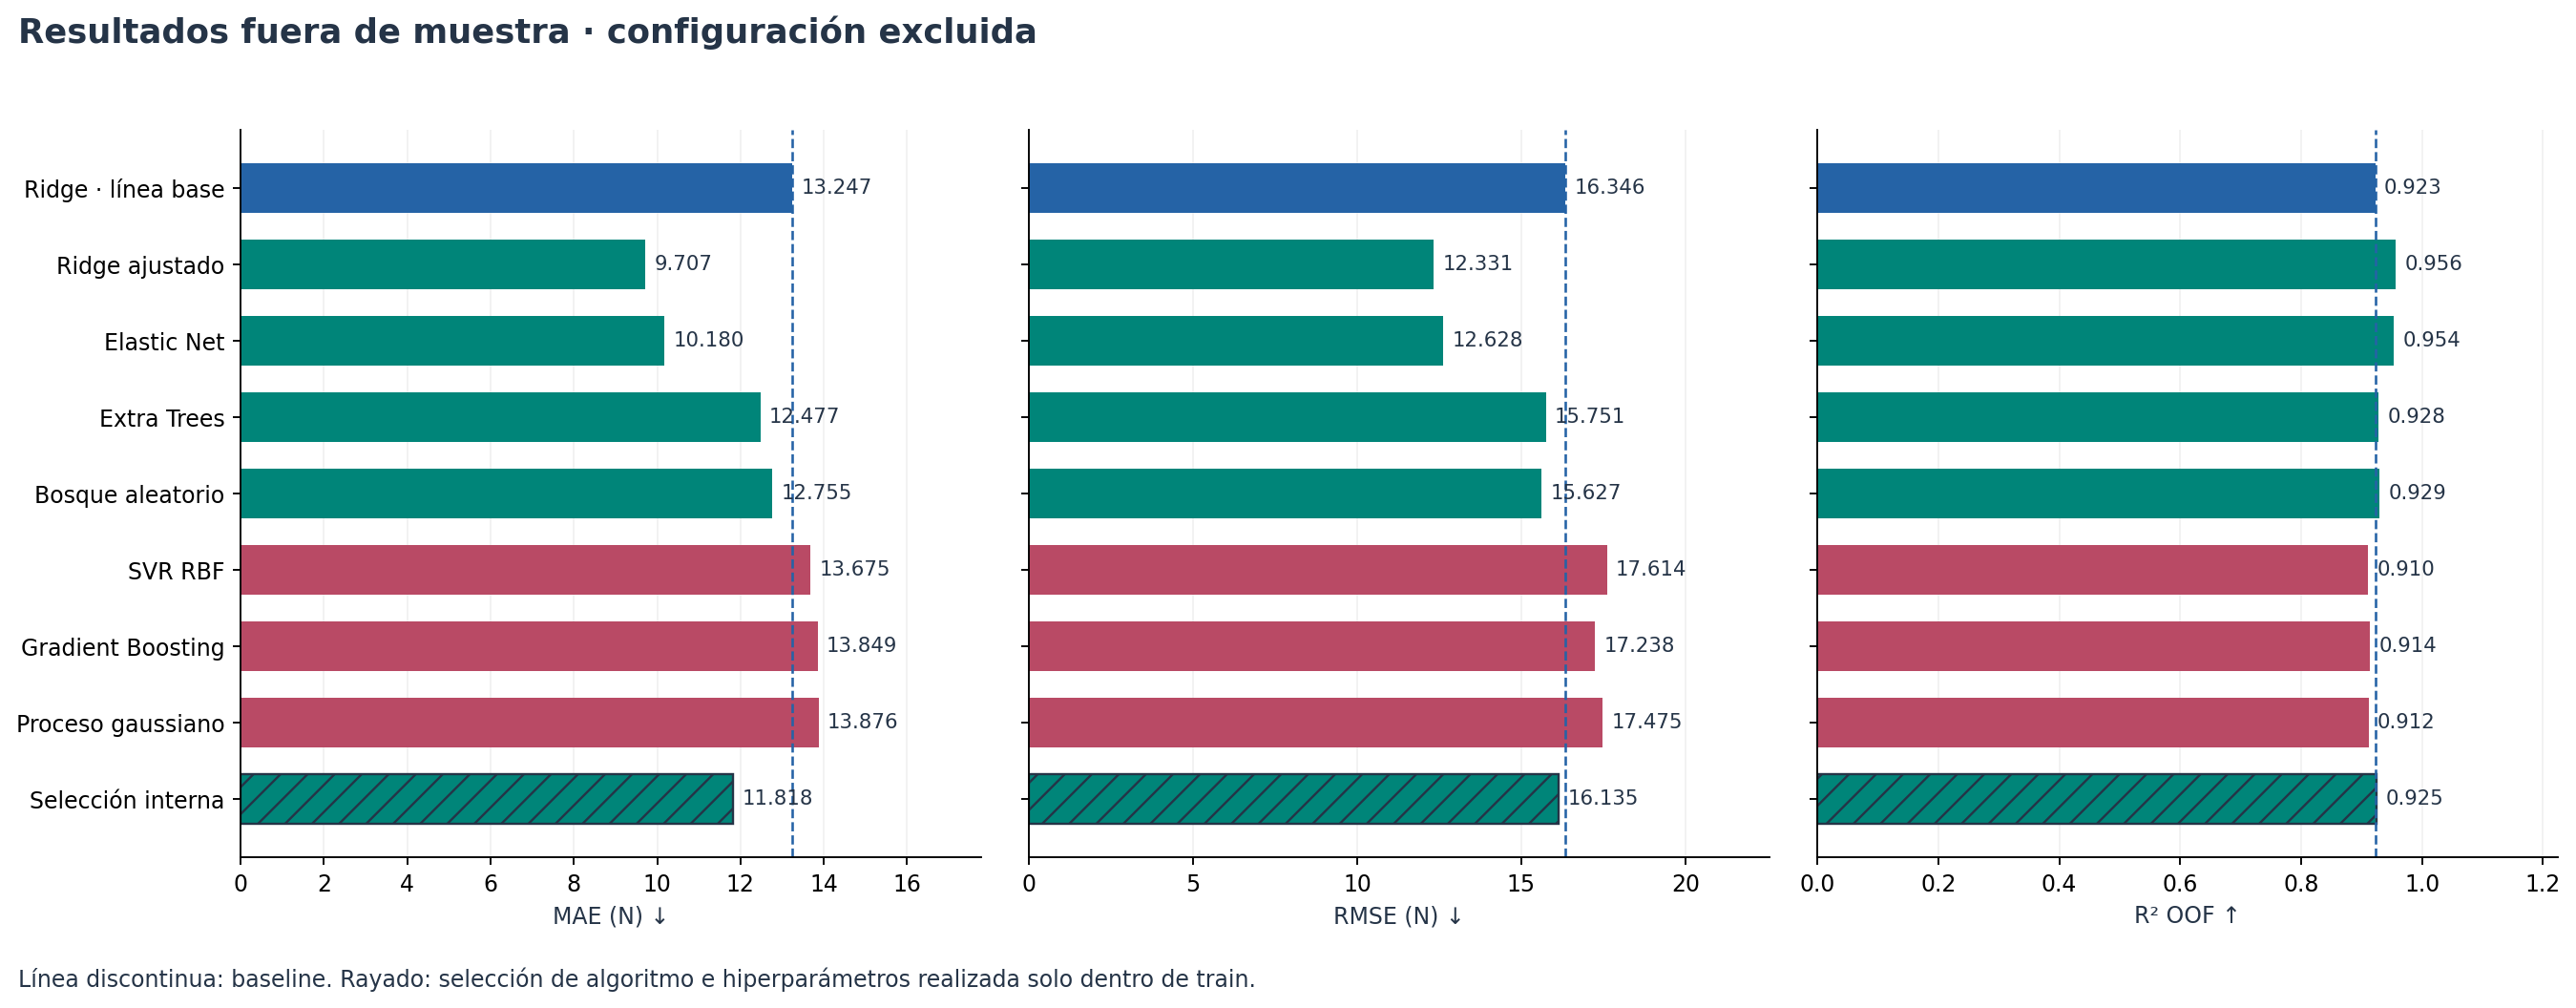

**Familia excluida — transferencia a otra arquitectura**

Modelo,MAE (N),RMSE (N),MedAE (N),R² OOF,Tiempo total CV (s),Reducción MAE (%)
Ridge · línea base,57.637,60.428,64.520,-0.058,0.038,0.000
Ridge ajustado,67.769,76.819,54.360,-0.710,0.492,-17.578
Elastic Net,58.214,62.368,54.110,-0.127,0.799,-1.001
Extra Trees,64.934,73.983,52.197,-0.586,3.280,-12.659
Bosque aleatorio,59.619,70.683,42.354,-0.448,4.522,-3.437
SVR RBF,81.327,86.730,82.165,-1.179,0.956,-41.101
Gradient Boosting,65.652,73.466,69.995,-0.564,7.744,-13.905
Proceso gaussiano,80.593,87.522,84.392,-1.219,0.476,-39.828
Selección interna,72.089,80.780,60.476,-0.891,18.269,-25.074


**Antes y después del ajuste — mismos algoritmos de la Semana 5**

Modelo,MAE fijo previo (N),MAE ajustado (N),Reducción MAE (%)
Ridge ajustado,13.247,9.707,+26.72
Elastic Net,13.979,10.180,+27.17
SVR RBF,15.651,13.675,+12.63
Bosque aleatorio,13.233,12.755,+3.61
Proceso gaussiano,16.058,13.876,+13.59


In [8]:
display(Markdown('**Configuración excluida — comparación principal**'))
display(informe.estilo_metricas(informe.tabla_metricas(resumen, 'configuracion')))
display(Image(filename=str(informe.figura_metricas(ejecucion))))
display(Markdown('**Familia excluida — transferencia a otra arquitectura**'))
display(informe.estilo_metricas(informe.tabla_metricas(resumen, 'familia')))
display(Markdown('**Antes y después del ajuste — mismos algoritmos de la Semana 5**'))
display(informe.antes_despues_ajuste(resumen).style.hide(axis='index').format(
    {'MAE fijo previo (N)': '{:.3f}', 'MAE ajustado (N)': '{:.3f}', 'Reducción MAE (%)': '{:+.2f}'})
    .background_gradient(subset=['Reducción MAE (%)'], cmap='RdYlGn', vmin=-20, vmax=20))

## 5.7 Predicciones, residuos y errores por grupo

        Cada punto proviene de una predicción realizada cuando su grupo estaba reservado.
        En los residuos, valores positivos indican subestimación de la carga de primera falla.

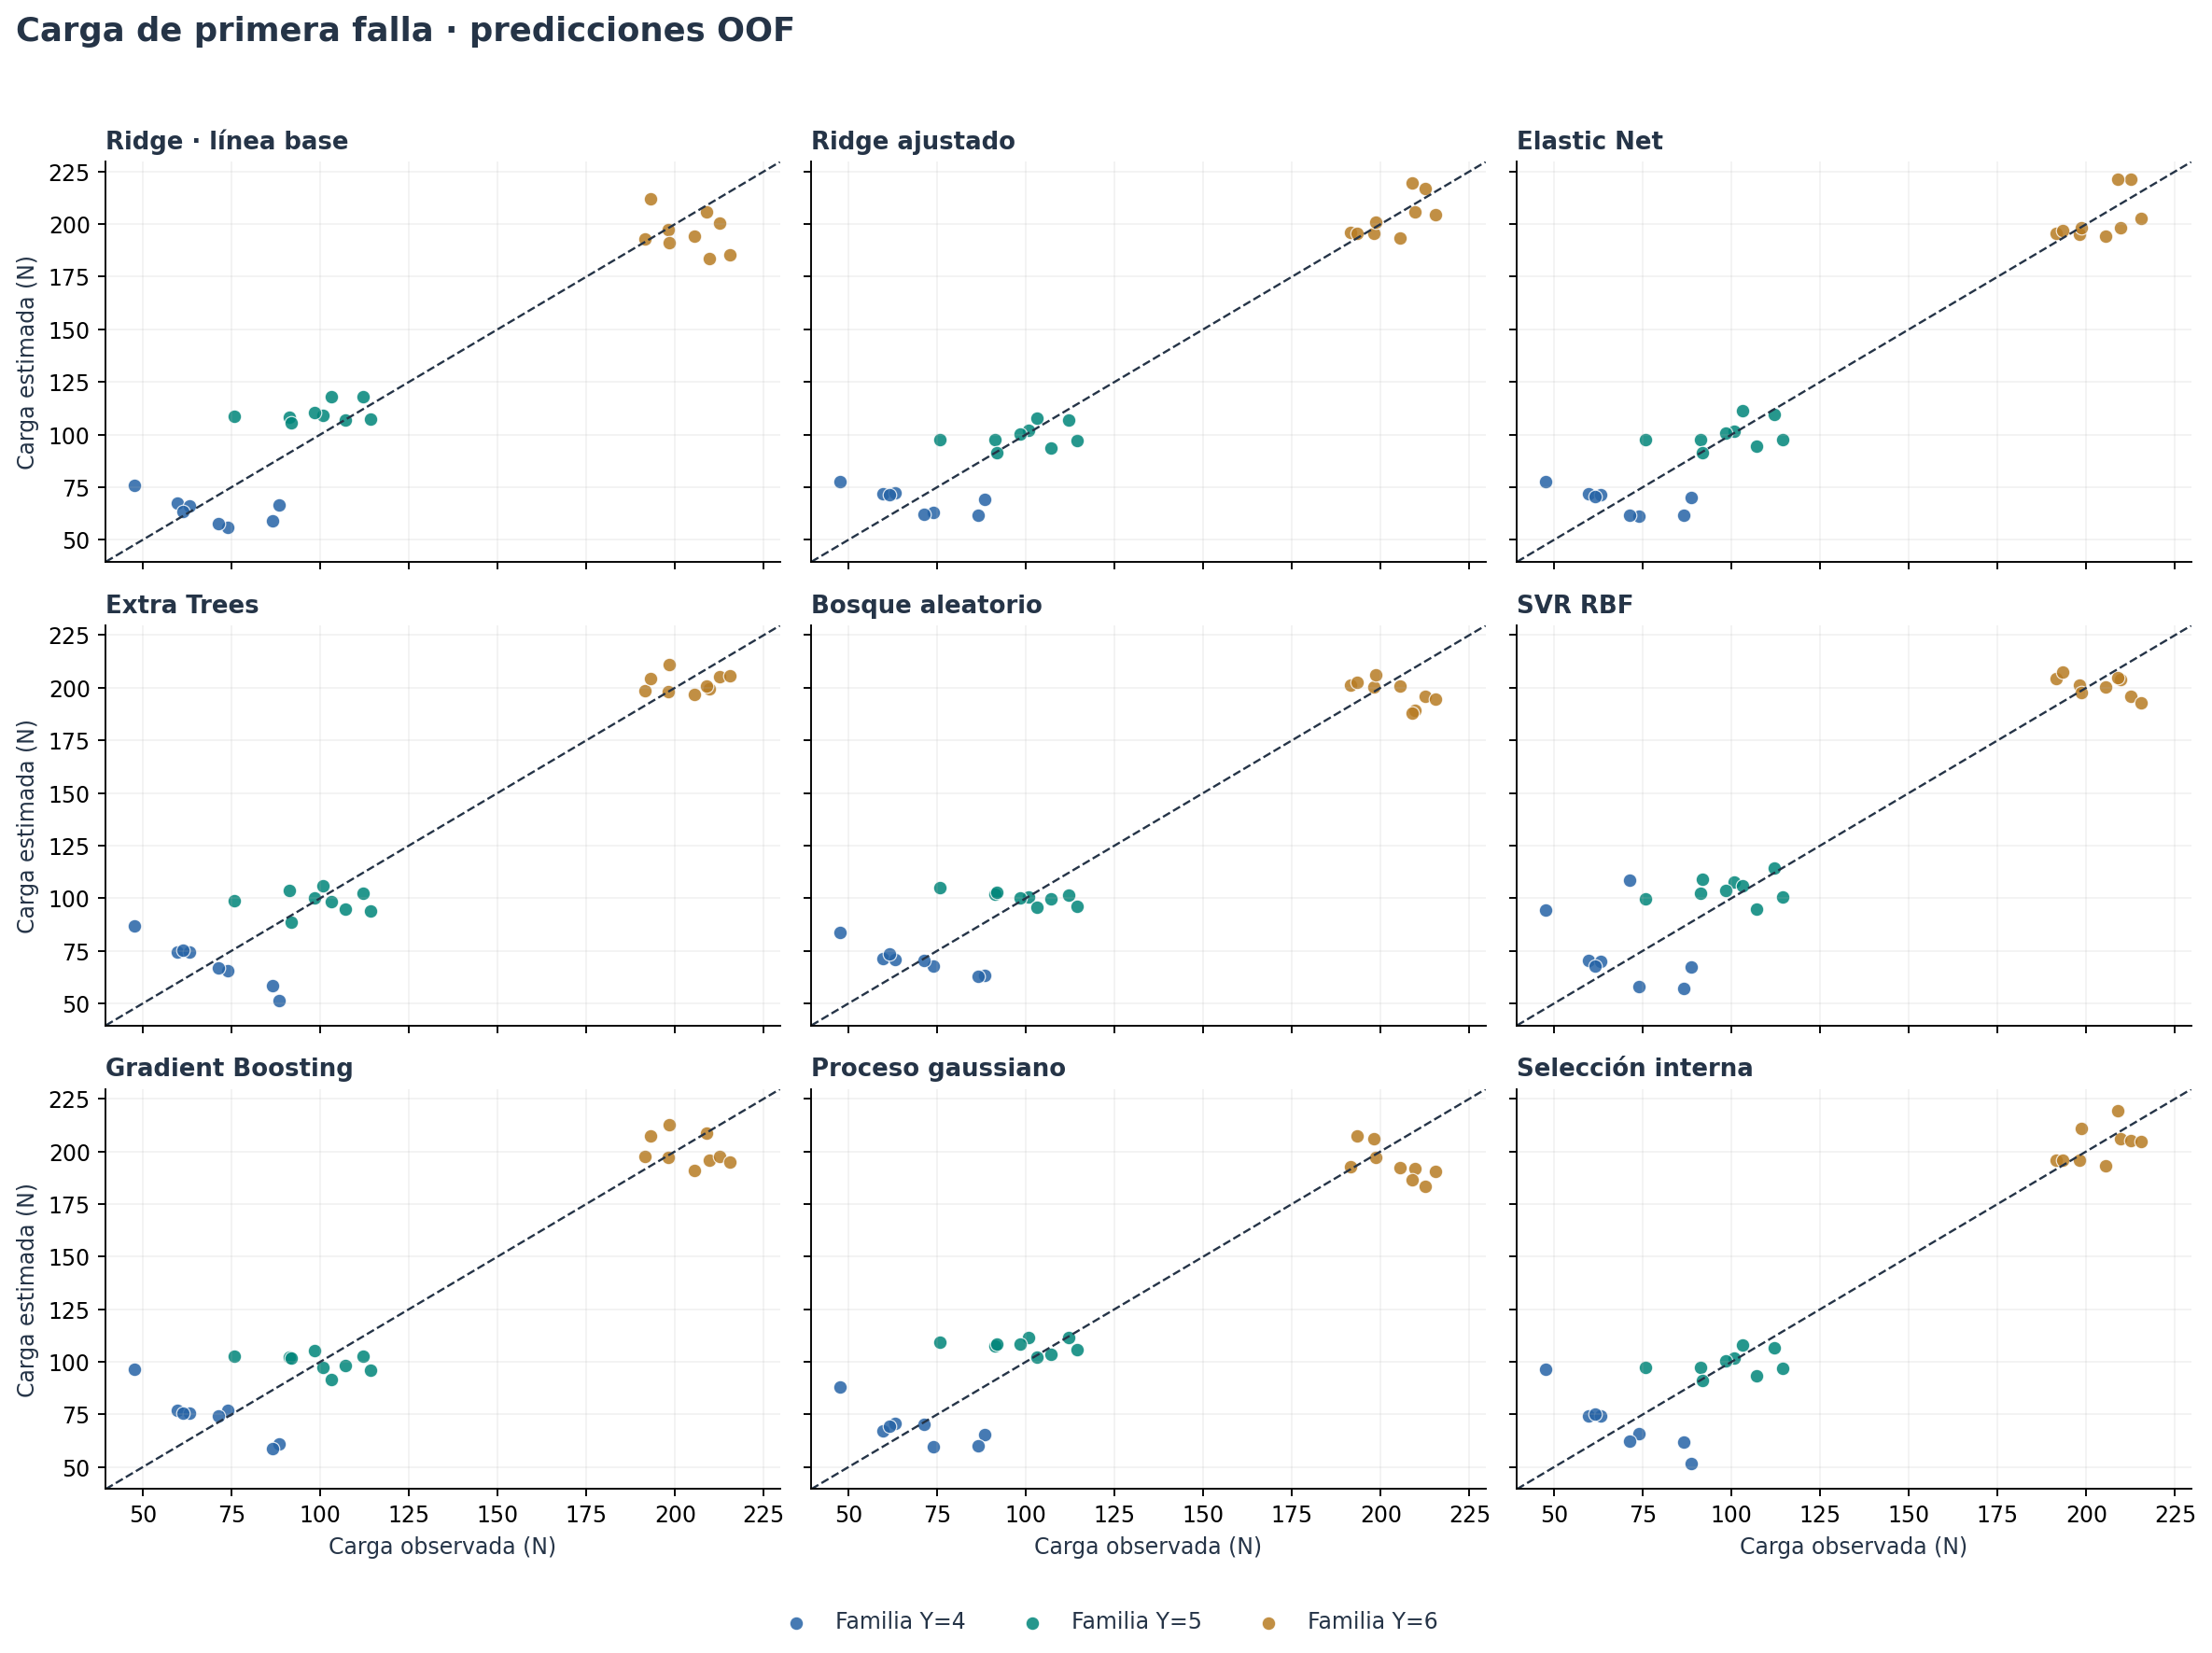

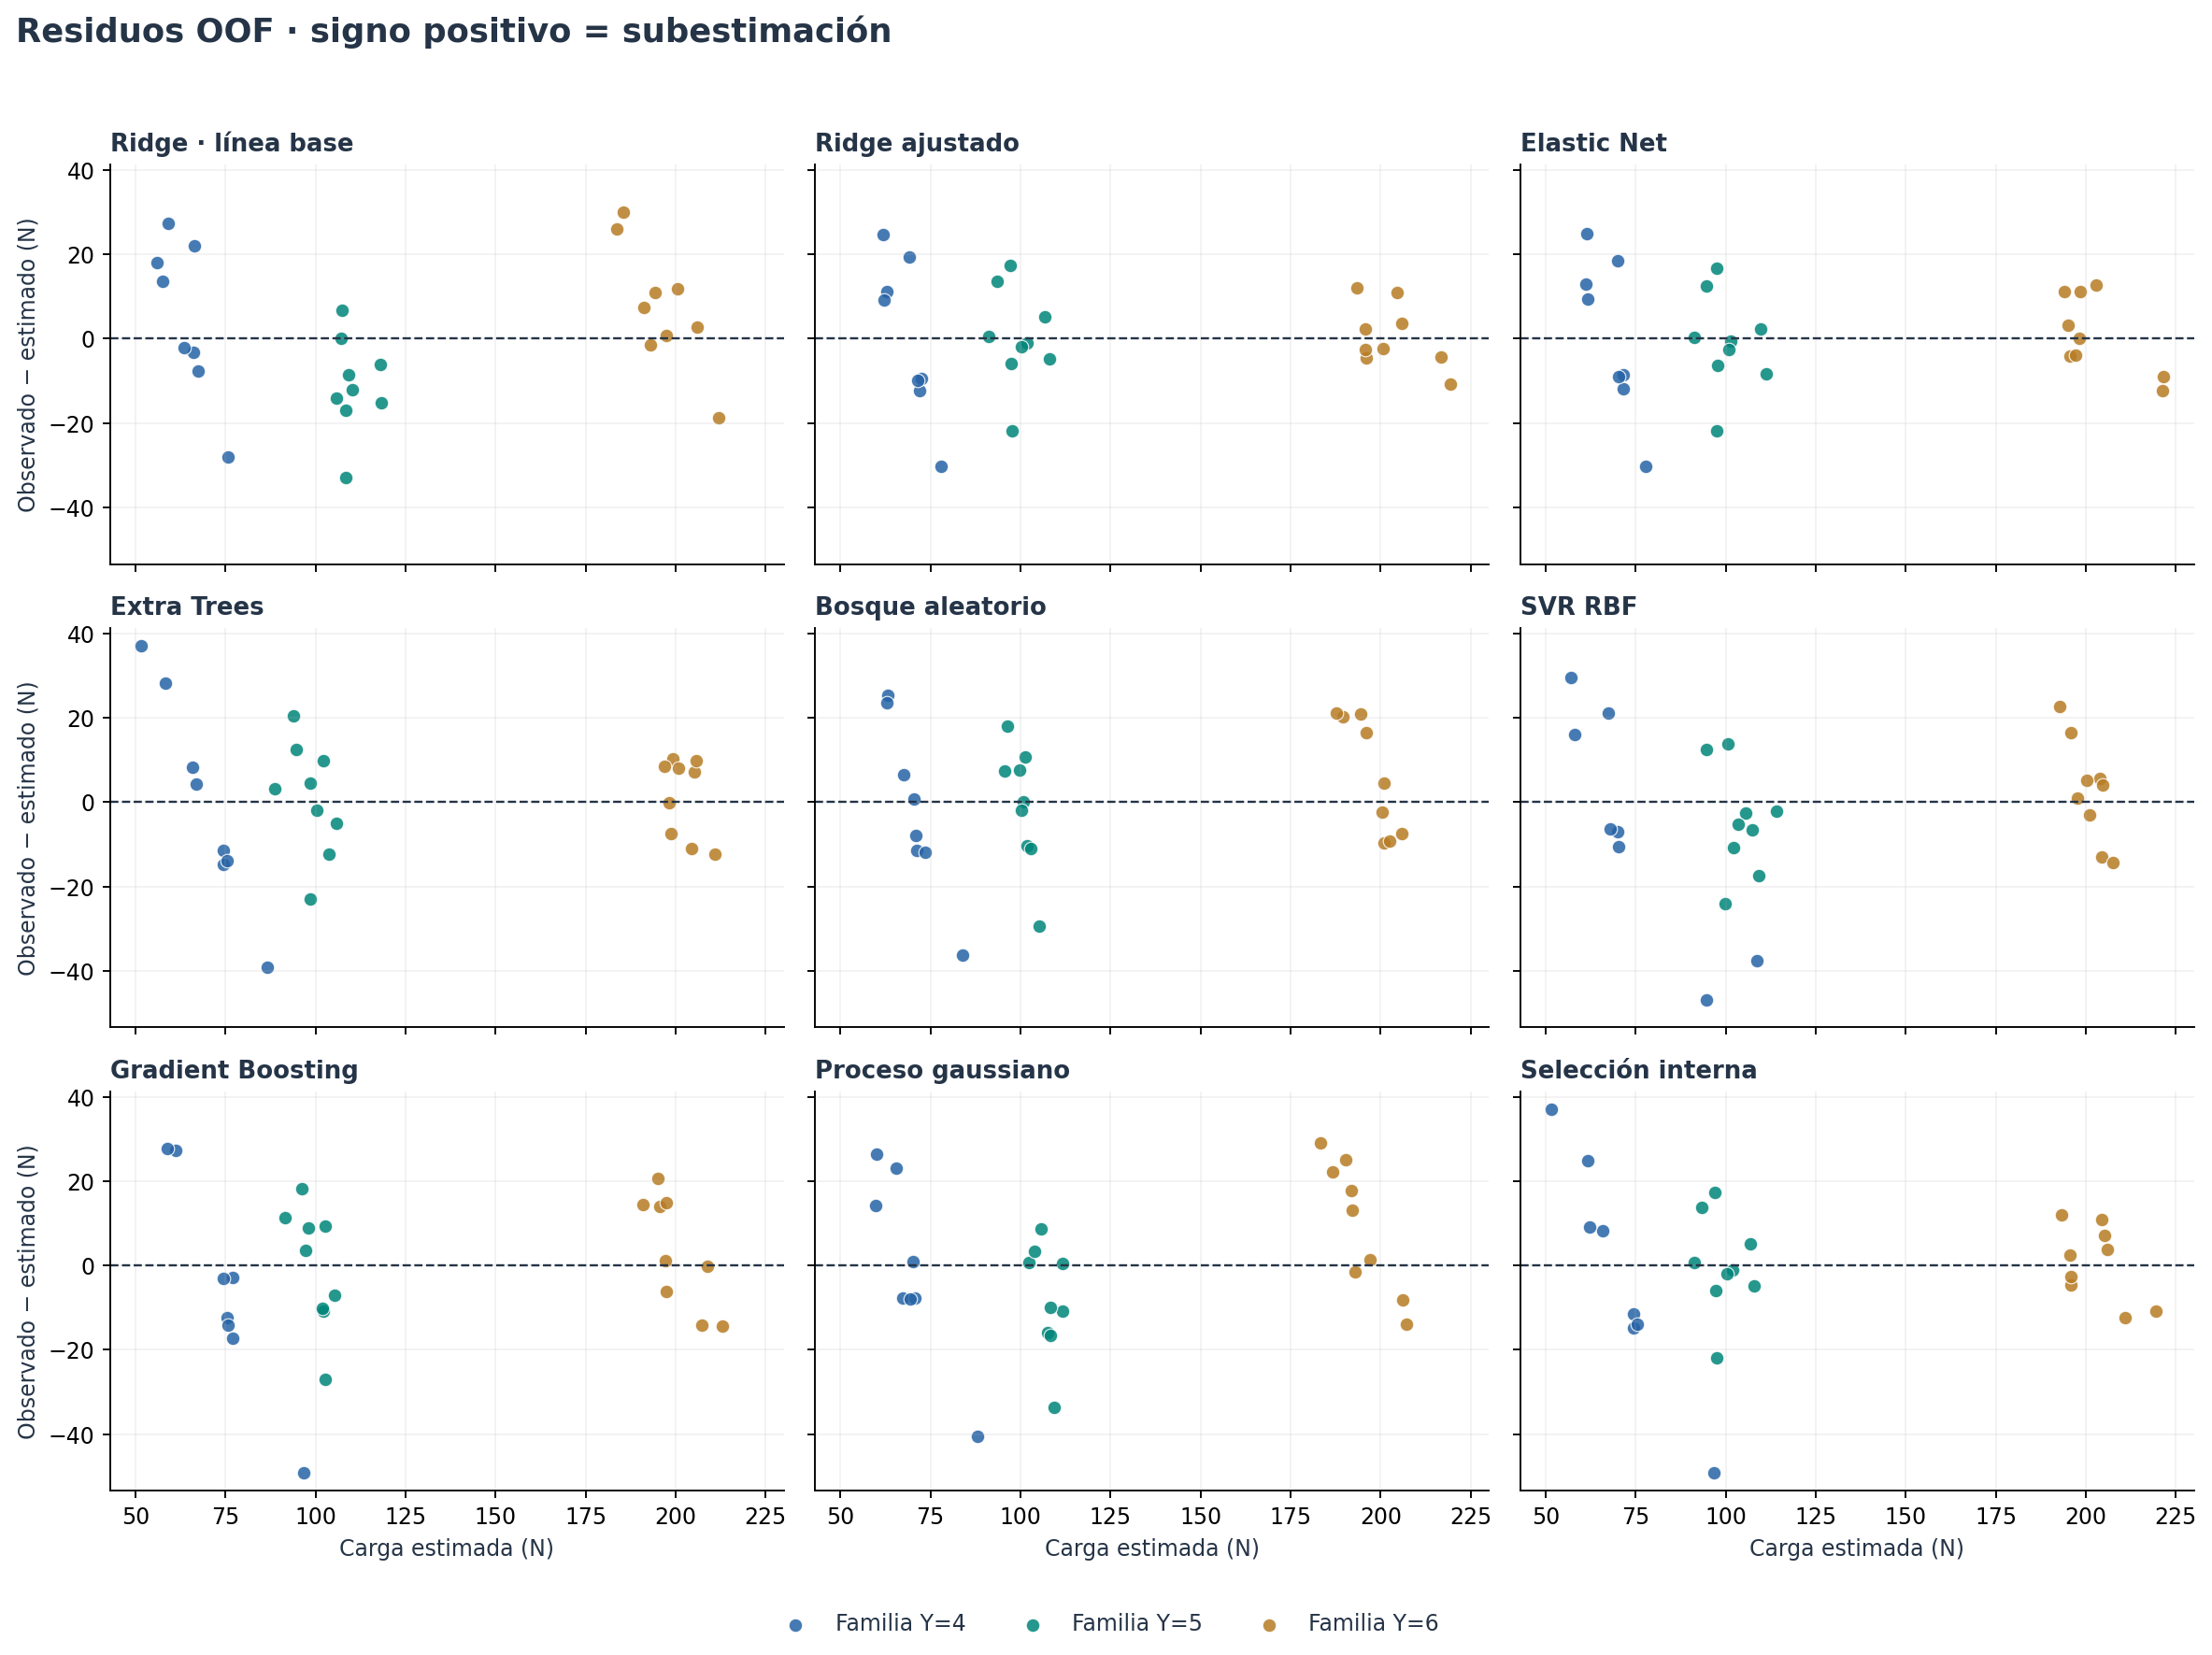

In [9]:
display(Image(filename=str(informe.figura_predicciones(ejecucion))))
display(Image(filename=str(informe.figura_predicciones(ejecucion, residuales=True))))

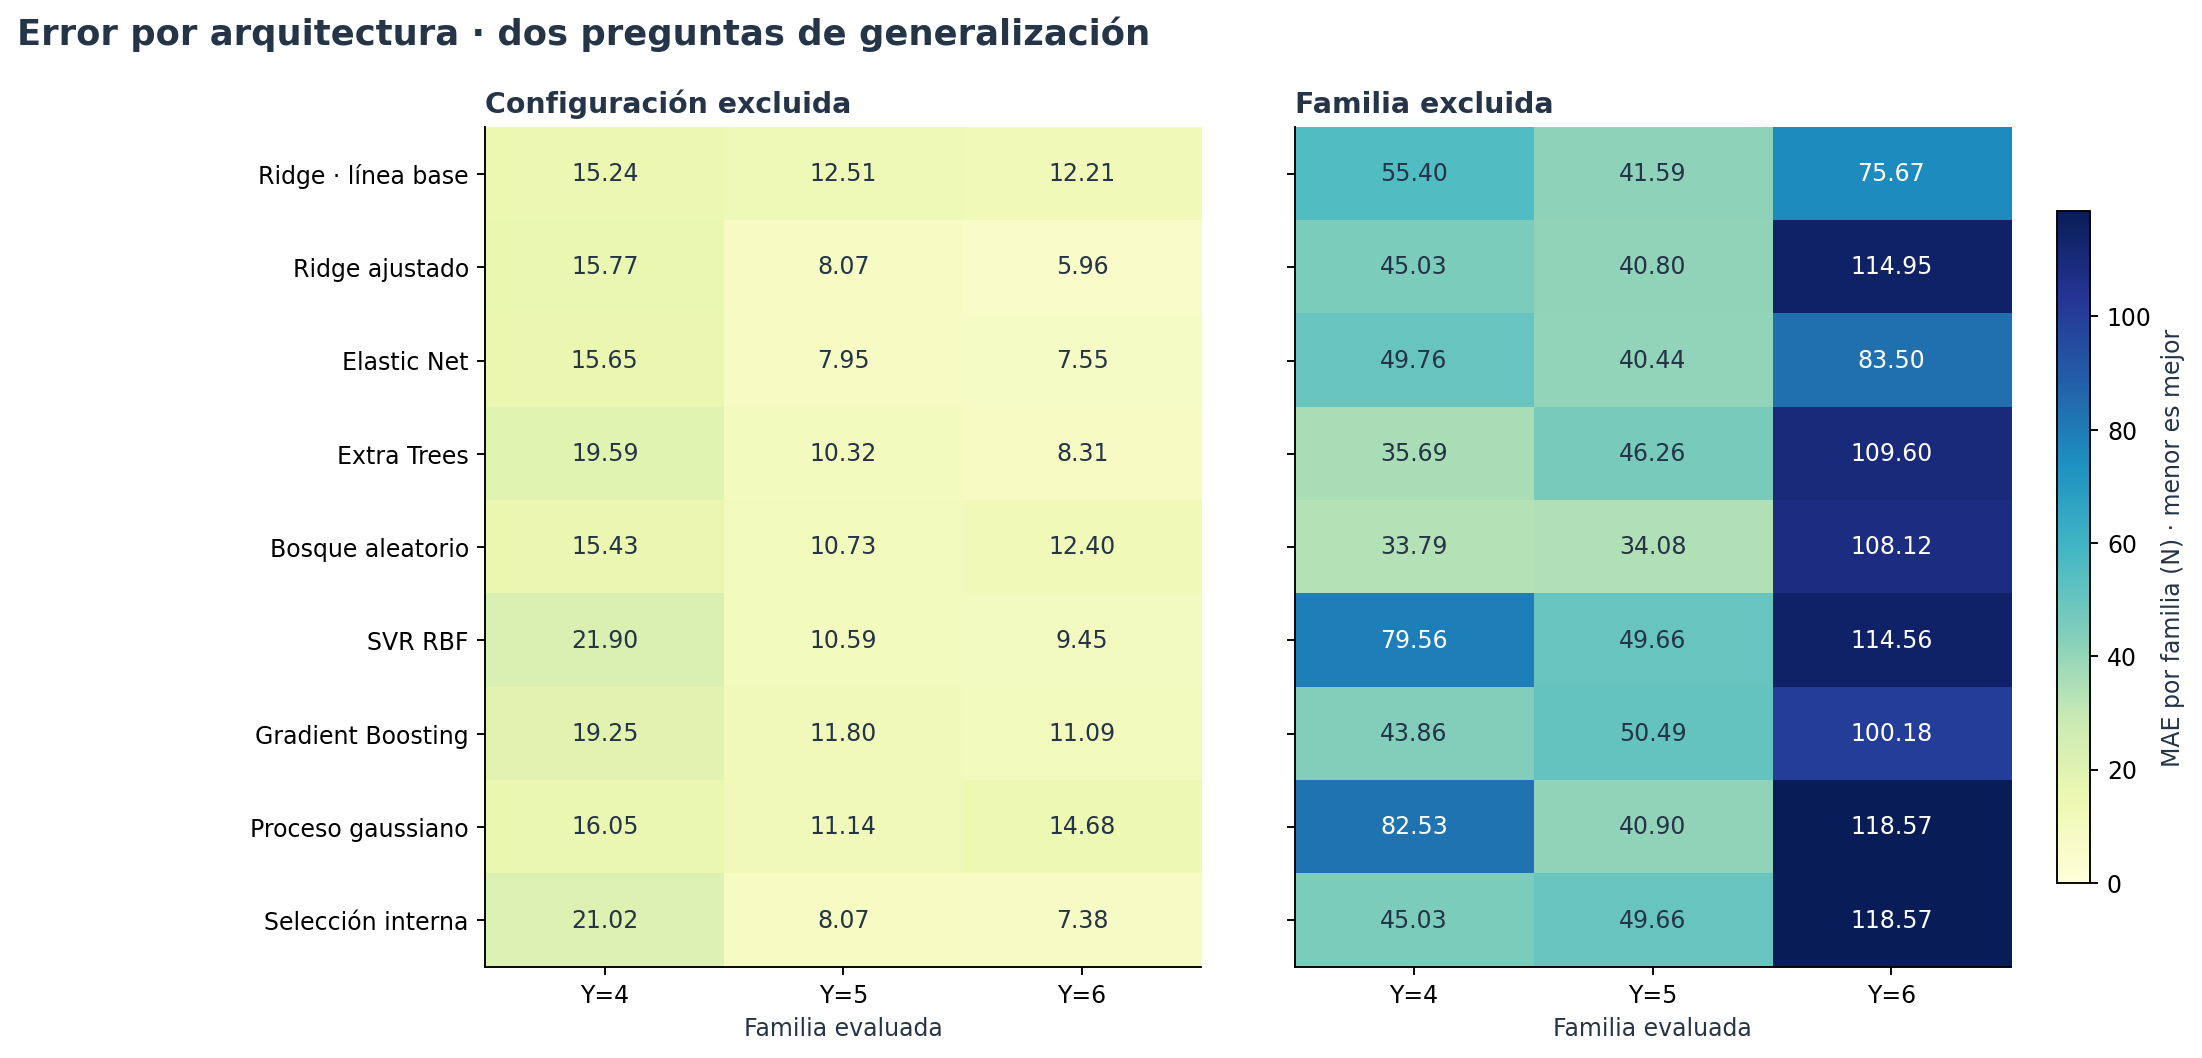

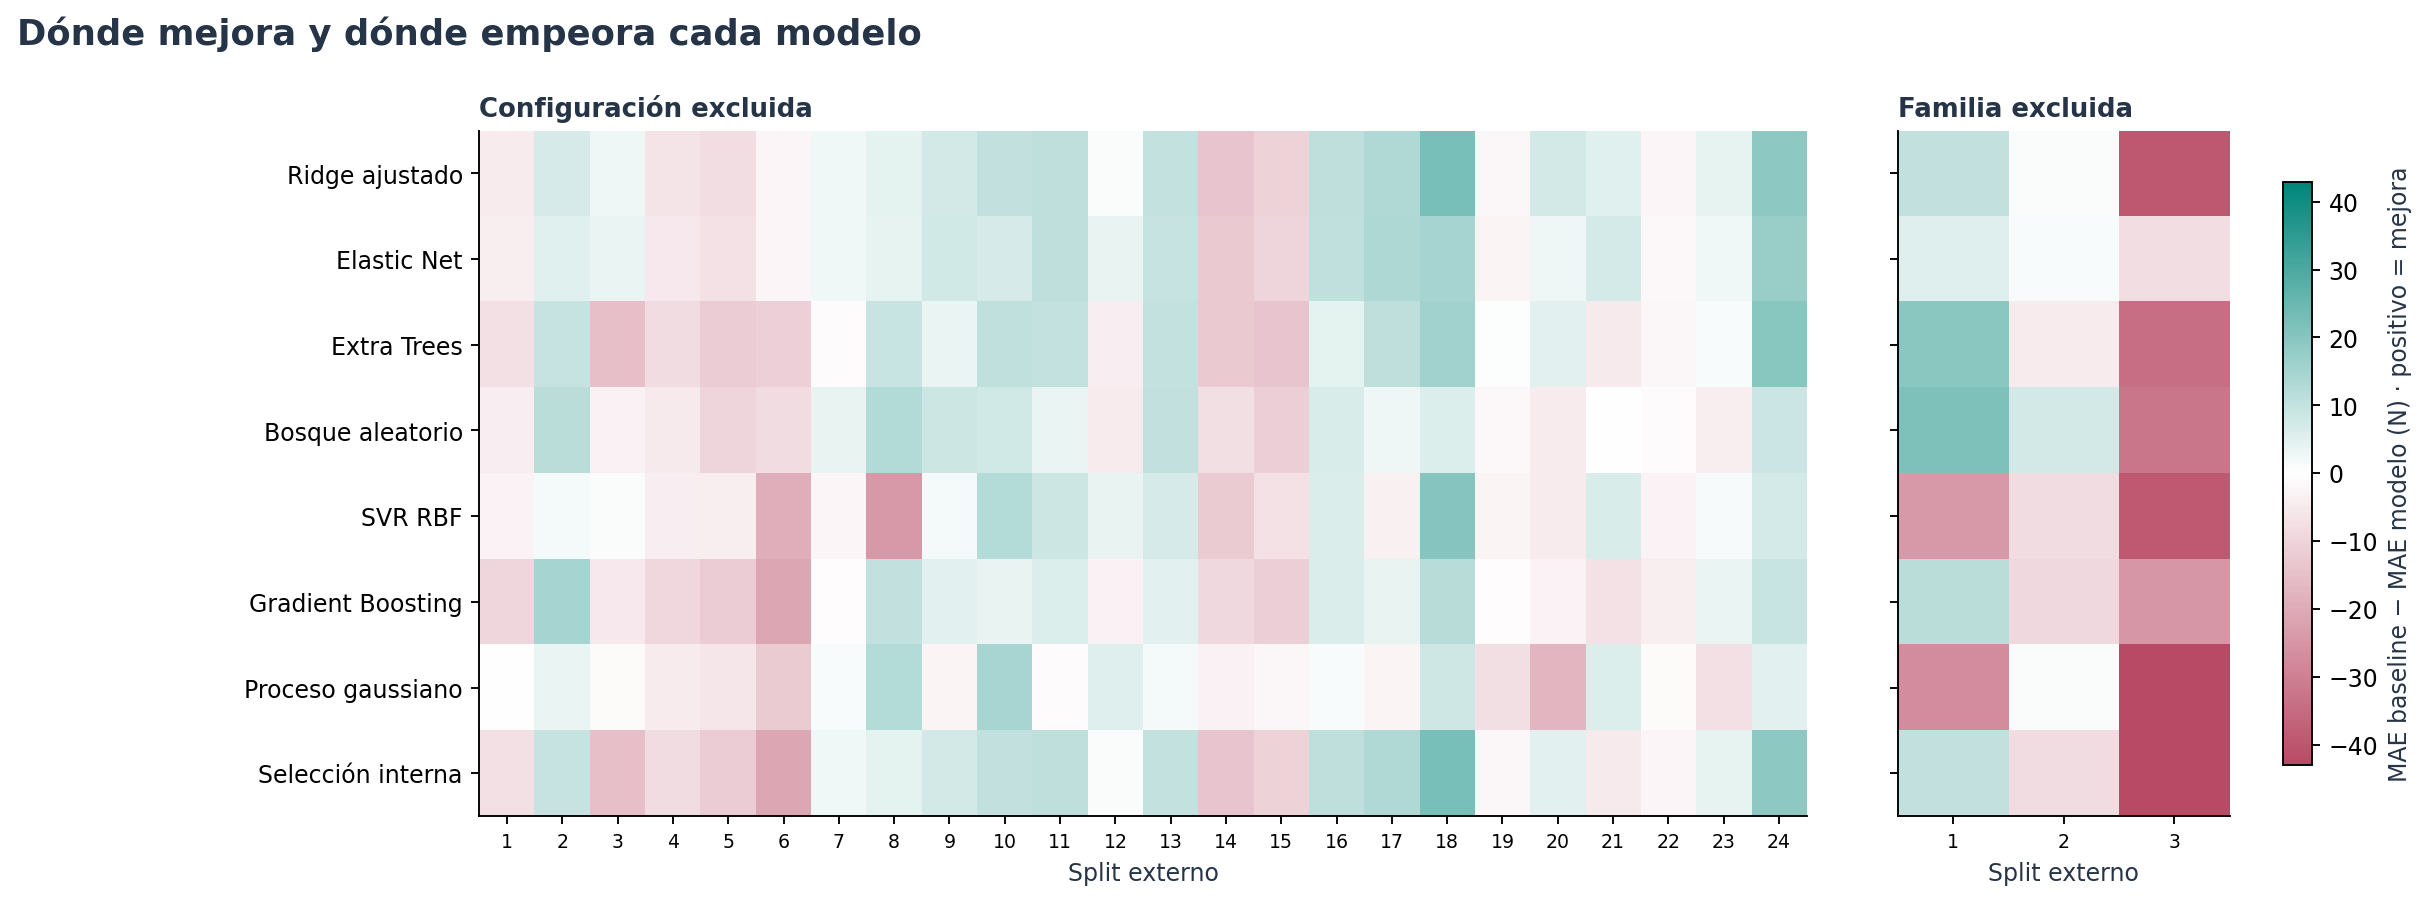

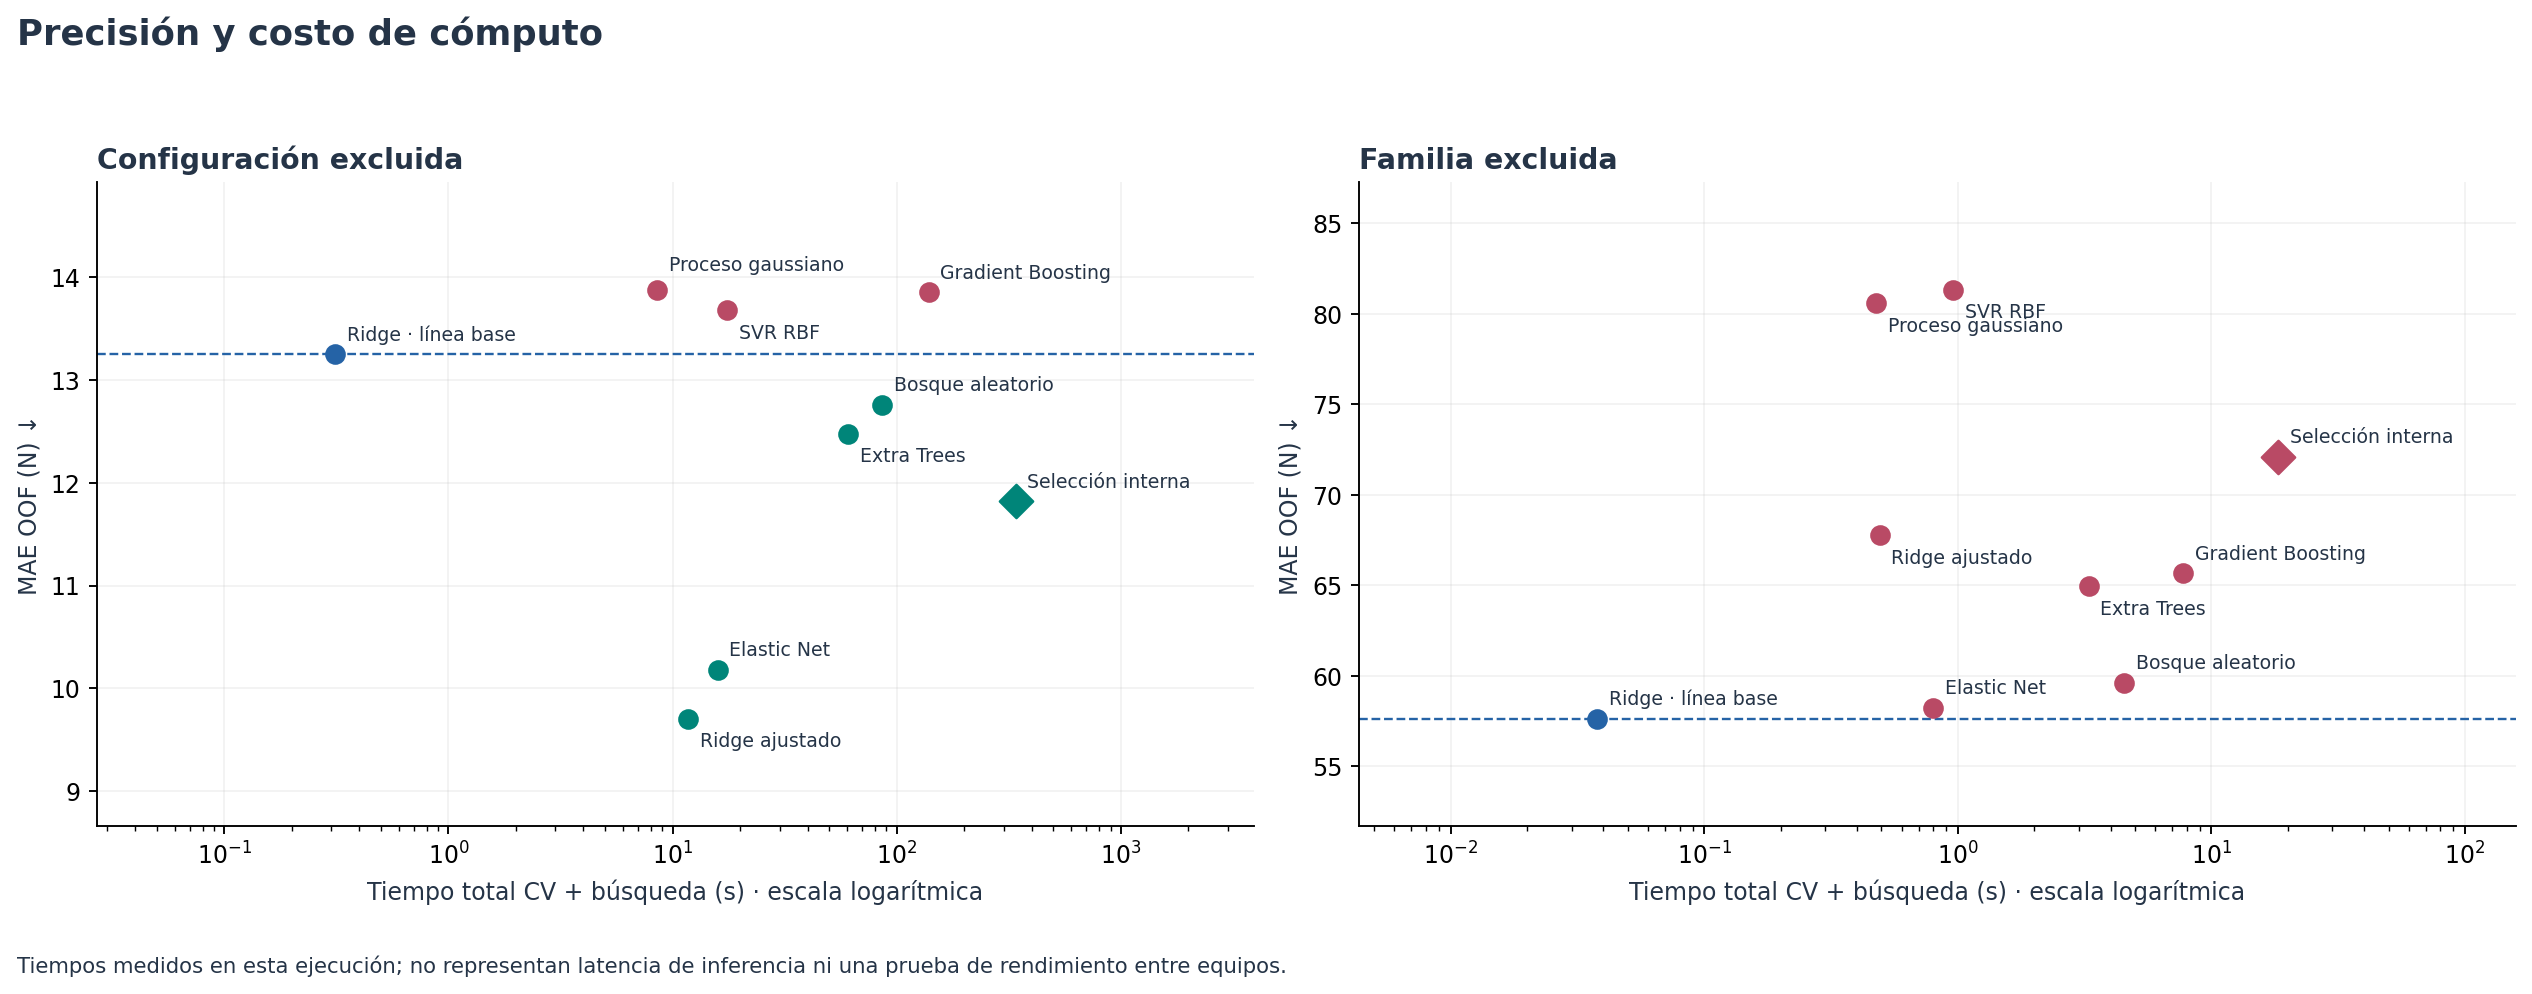

In [10]:
display(Image(filename=str(informe.figura_familias(ejecucion))))
display(Image(filename=str(informe.figura_mejora_folds(ejecucion))))
display(Image(filename=str(informe.figura_costo(ejecucion))))

## 5.8 Estabilidad del ajuste

        La frecuencia indica qué parámetros o algoritmo eligió la validación interna de cada split.
        No mide importancia de variables ni probabilidad de que un modelo sea el mejor.

Modelo,Combinación más frecuente,Frecuencia de selección (%)
Elastic Net,alpha=0.001; l1_ratio=0.9,95.830000
Extra Trees,max_depth=None; max_features=1.0; min_samples_leaf=2,50.000000
Proceso gaussiano,"alpha=0.05; kernel=Matern(length_scale=10, nu=1.5)",100.000000
Gradient Boosting,learning_rate=0.03; loss=squared_error; max_depth=1; n_estimators=100,33.330000
Bosque aleatorio,max_depth=None; max_features=sqrt; min_samples_leaf=2,62.500000
Ridge ajustado,alpha=0.0001,91.670000
SVR RBF,C=1000.0; epsilon=5.0; gamma=0.01,83.330000


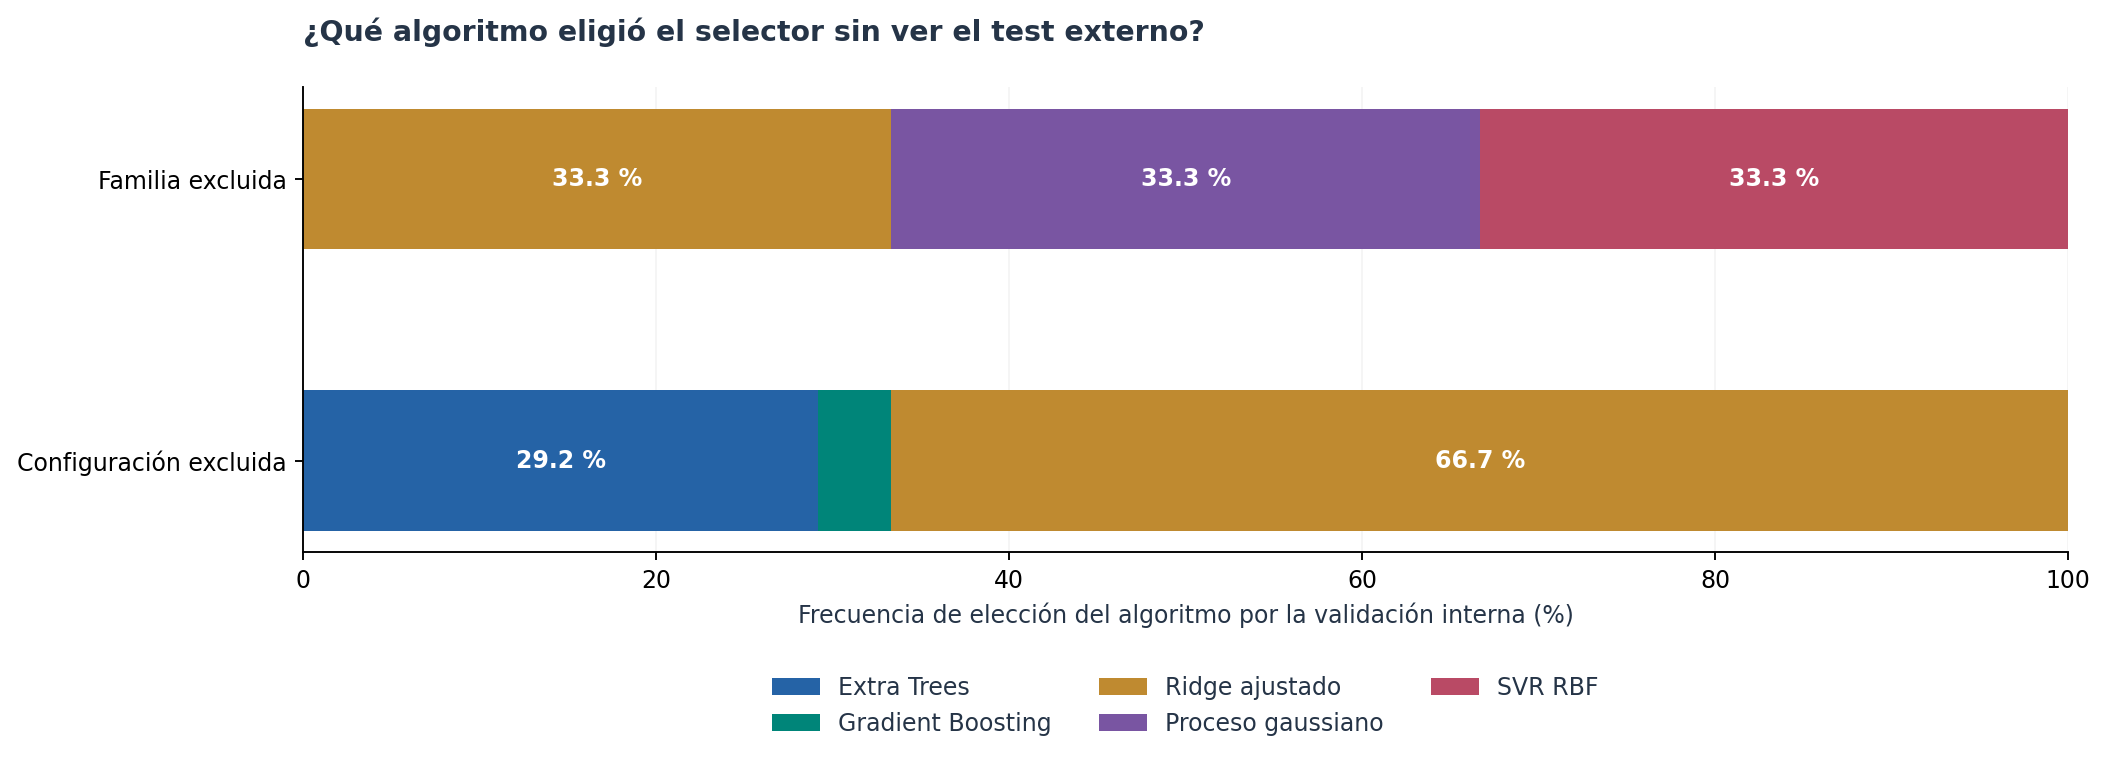

In [11]:
frecuencia_parametros, frecuencia_modelos = informe.frecuencias_ajuste(ejecucion)
display(frecuencia_parametros.style.hide(axis='index')
    .set_properties(subset=['Combinación más frecuente'], **{'max-width':'470px', 'white-space':'normal'}))
display(Image(filename=str(informe.figura_seleccion(ejecucion, frecuencia_modelos))))

## 5.9 Interpretación de resultados

In [12]:
display(Markdown(informe.interpretacion(ejecucion)))

**Ranking descriptivo:** Ridge ajustado obtuvo MAE **9.707 N**, frente a **13.247 N** del baseline (+26.72 % de reducción). Elegirlo después de comparar estos resultados requiere una evaluación independiente posterior.

**Selección anidada:** al elegir algoritmo y parámetros solo en validación interna, el MAE externo fue **11.818 N** (+10.79 % frente al baseline). Este resultado evalúa el procedimiento de selección completo.

**Familias nuevas:** Ridge ajustado obtuvo MAE **67.769 N** (+17.58 % de variación del error frente al baseline). Selección interna obtuvo MAE **72.089 N** y R² **-0.891** al reservar familias completas. El R² negativo indica que la transferencia a otras arquitecturas no está resuelta.

**Ajuste de Ridge:** predominó una regularización baja y se alcanzó el límite inferior de la rejilla. El resultado no demuestra un óptimo global; la búsqueda declarada se mantiene.

**Alcance:** el ajuste respeta las particiones y aprende el preprocesamiento solo con train. El EDA previo utilizó esta campaña completa; no existe un holdout externo intacto. Estas métricas no demuestran desempeño en producción ni permiten afirmar significancia estadística.

## 5.10 Reproducibilidad

        Configuración, semillas, timestamps, búsqueda completa, particiones internas, estadísticas de train,
        predicciones OOF y métricas quedan en [los artefactos de ejecución](../reports/modelos_ajustados/).

In [13]:
auditoria = informe.leer_json(RUN_DIR / 'verificacion.json')
display(pd.DataFrame([
    {'Control': 'Auditoría ejecutada', 'Resultado': auditoria['status']},
    {'Control': 'Fecha UTC de comprobación', 'Resultado': auditoria.get('checked_utc', '')},
    {'Control': 'Snapshot después de evaluar', 'Resultado': informe.huella(ruta_datos)},
    {'Control': 'Snapshot sin cambios', 'Resultado': informe.huella(ruta_datos) == hash_datos},
    {'Control': 'Semilla declarada', 'Resultado': SEMILLA},
]).style.hide(axis='index'))
assert informe.huella(ruta_datos) == hash_datos

Control,Resultado
Auditoría ejecutada,passed
Fecha UTC de comprobación,2026-10-24T02:47:29.004885+00:00
Snapshot después de evaluar,2d0a17f54bdc6a6361aaa6e25a57cf67775c7d47a5e2adefb408f114defa21f8
Snapshot sin cambios,True
Semilla declarada,42


Reproducir el notebook publicado y comprobar sus resultados:

        ```bash
        python -m src.reporte_ajuste --execute
        ```

        Entrenar otra ejecución por consola, usando una carpeta que aún no exista:

        ```bash
        python -m src.ajuste_modelos --output logs/modelos_ajustados/repeticion_01
        python -m src.verificar_ajuste --run-dir logs/modelos_ajustados/repeticion_01
        ```

        Para entrenar y visualizar una ejecución nueva desde este cuaderno, usar `REEJECUTAR = True` en 5.5.
        Las ejecuciones por consola no sustituyen automáticamente los resultados publicados.

        Código: [experimento](../src/ajuste_modelos.py), [verificación](../src/verificar_ajuste.py),
        [figuras y notebook](../src/reporte_ajuste.py).
        Referencias técnicas: [validación anidada](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_nested_cross_validation_iris.html),
        [prevención de fuga de información](https://scikit-learn.org/1.7/common_pitfalls.html).